In [47]:
from sklearn import set_config
set_config(display="text")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

from sklearn.model_selection import train_test_split   #---- 문제답 분리

import tensorflow as tf
tf.random.set_seed(1234)
np.random.seed(1234)
    
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D  #---- CNN
from keras.layers import Dense, Flatten        #---- FC

from tensorflow.keras.applications import MobileNet, Xception  #----잘알려진모델
from tensorflow.keras.models import save_model, load_model

# **Data Load**

In [2]:
MY_BASE_PATH =  "C:\\IT\\python_workspace\\datas\\catdog\\train"
train_dir = os.listdir(MY_BASE_PATH)
train_dir

['cat', 'dog']

In [3]:
train_dir_cat = os.path.join(MY_BASE_PATH, "cat")
train_dir_dog = os.path.join(MY_BASE_PATH, "dog")
train_dir_cat, train_dir_dog

('C:\\IT\\python_workspace\\datas\\catdog\\train\\cat',
 'C:\\IT\\python_workspace\\datas\\catdog\\train\\dog')

In [4]:
#cat_img_list = os.listdir("C:\\IT\\python_workspace\\datas\\catdog\\train\\cat")
cat_img_list = os.listdir(train_dir_cat)
dog_img_list = os.listdir(train_dir_dog)
print( len(cat_img_list) , cat_img_list[:10] )
print( len(dog_img_list) , dog_img_list[:10] )

231 ['cat.0.jpg', 'cat.1.jpg', 'cat.10.jpg', 'cat.100.jpg', 'cat.101.jpg', 'cat.102.jpg', 'cat.103.jpg', 'cat.104.jpg', 'cat.105.jpg', 'cat.106.jpg']
231 ['dog.0.jpg', 'dog.1.jpg', 'dog.10.jpg', 'dog.100.jpg', 'dog.101.jpg', 'dog.102.jpg', 'dog.103.jpg', 'dog.104.jpg', 'dog.105.jpg', 'dog.106.jpg']


# **EDA**

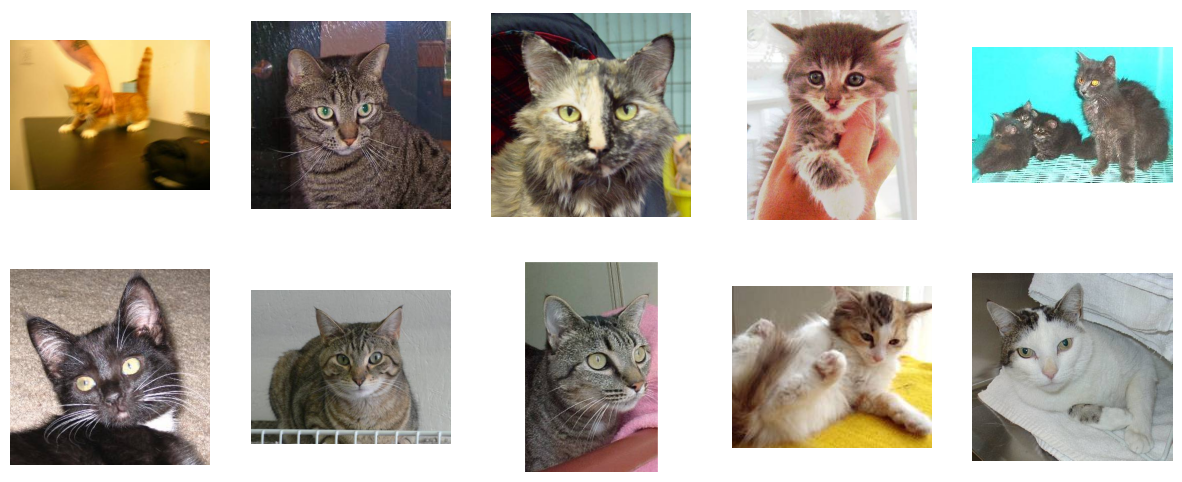

In [5]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
for i, img_path in enumerate(cat_img_list[:10]):
  sp = plt.subplot(2, 5, i + 1)
  sp.axis('Off') 
  img = mpimg.imread(train_dir_cat + "\\" +img_path)
  plt.imshow(img)
plt.show()

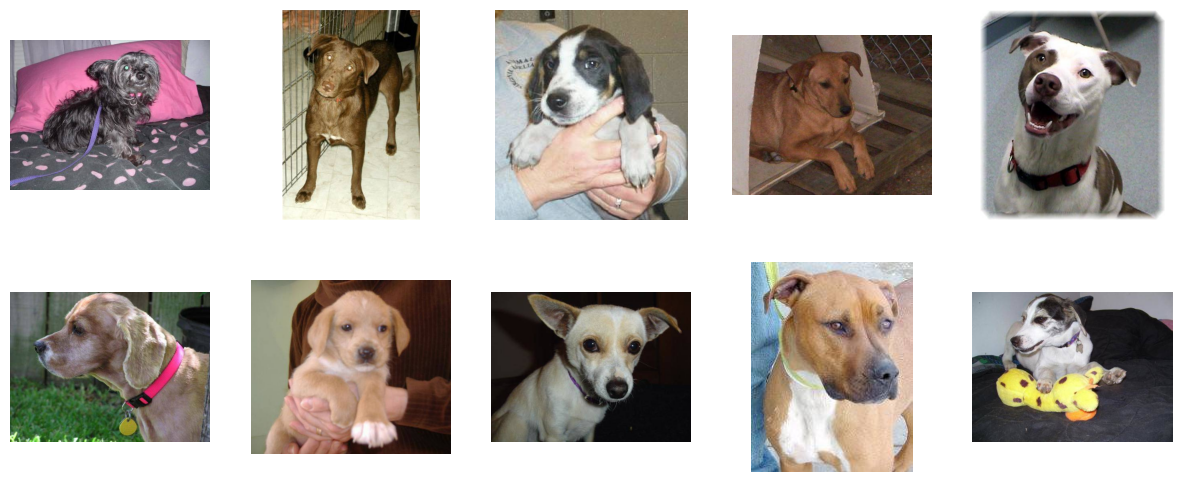

In [6]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
for i, img_path in enumerate(dog_img_list[:10]):
  sp = plt.subplot(2, 5, i + 1)
  sp.axis('Off') 
  img = mpimg.imread(train_dir_dog + "\\" +img_path)
  plt.imshow(img)
plt.show()

# **전처리 & 가공**
* 스케일링

In [7]:
tf.__version__

'2.21.0'

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [9]:
train_datagen = ImageDataGenerator( rescale = 1.0 / 255.0)
val_datagen   = ImageDataGenerator( rescale = 1.0 / 255.0)
test_datagen  = ImageDataGenerator( rescale = 1.0 / 255.0)

<pre>
<b>flow_from_directory()</b>
catdog
   train
      cat  --- 0
      dog  --- 1
   val
      cat  --- 0
      dog  --- 1
   test
      test --- ?

In [10]:
#train_dir_cat = os.path.join(MY_BASE_PATH, "cat")
#train_dir_dog = os.path.join(MY_BASE_PATH, "dog")

TRAIN_PATH = "C:\\IT\\python_workspace\\datas\\catdog\\train"
VAL_PATH   = "C:\\IT\\python_workspace\\datas\\catdog\\val"

train_gen = train_datagen.flow_from_directory(TRAIN_PATH, batch_size=20, class_mode = 'binary',  target_size=(240, 160))
val_gen   = val_datagen.flow_from_directory(VAL_PATH  , batch_size=20, class_mode = 'binary',  target_size=(240, 160))

Found 462 images belonging to 2 classes.
Found 140 images belonging to 2 classes.


# **모델 생성 및 학습**

* 사진크기 (240 , 160)

In [12]:
model = Sequential([
    Conv2D(filters=12, kernel_size=(5,5), strides=(1, 1), padding='valid', activation='relu', input_shape=(240,160,3)) ,    
    MaxPooling2D(pool_size=(2, 2)) ,
    Conv2D(filters=16, kernel_size=(5,5), strides=(1, 1), padding='valid', activation='relu') ,    
    MaxPooling2D(pool_size=(2, 2)) ,
    Conv2D(filters=20, kernel_size=(4,4), strides=(1, 1), padding='valid', activation='relu') ,    
    MaxPooling2D(pool_size=(2, 2)) ,
    Flatten(),
    Dense(units=512, activation='relu'),
    Dense(units=128, activation='relu'),
    Dense(units=1,   activation='sigmoid')
])
model.compile(loss="binary_crossentropy" , optimizer="adam",  metrics=['accuracy'] )

C:\IT\python_workspace\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 236, 156, 12)        │             912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 118, 78, 12)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 114, 74, 16)         │           4,816 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 57, 37, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 54, 34, 20)          │           5,140 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 27, 17, 20)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 9180)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       4,700,672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,777,333 (18.22 MB)

 Trainable params: 4,777,333 (18.22 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
#fit_res = model.fit(X_train, y_train, batch_size=256, epochs=40, validation_data=(X_test, y_test) )
fit_res = model.fit(train_gen, epochs=30,   validation_data=val_gen )

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - accuracy: 0.5216 - loss: 0.7109 - val_accuracy: 0.5000 - val_loss: 0.6876
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.4697 - loss: 0.6944 - val_accuracy: 0.5000 - val_loss: 0.6869
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.5173 - loss: 0.6841 - val_accuracy: 0.5643 - val_loss: 0.6845
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - accuracy: 0.5498 - loss: 0.6826 - val_accuracy: 0.5571 - val_loss: 0.6865
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.6537 - loss: 0.6293 - val_accuracy: 0.5643 - val_loss: 0.7375
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.6991 - loss: 0.5686 - val_accuracy: 0.5786 - val_loss: 0.6999
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.7965 - loss: 0.4563 - val_accuracy: 0.6000 - val_loss: 0.6954
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.8355 - loss: 0.3745 - val_accuracy: 0.6214 - v

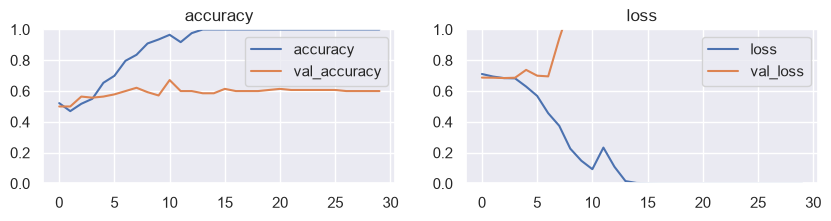

In [15]:
plt.figure(figsize=(10,2))
ax1 = plt.subplot(1,2,1)
ax1.plot(fit_res.history['accuracy']   ,   label="accuracy")
ax1.plot(fit_res.history['val_accuracy'],  label="val_accuracy")
ax1.legend()
ax1.set_ylim(0, 1.0)
ax1.set_title("accuracy")

ax2 = plt.subplot(1,2,2)
ax2.plot(fit_res.history['loss']   ,   label="loss")
ax2.plot(fit_res.history['val_loss'],  label="val_loss")
ax2.legend()
ax2.set_ylim(0, 1.0)
ax2.set_title("loss")

plt.show()


# **모델 저장**

In [21]:
model.save("./lec03_catdog_model.keras")

In [22]:
re_model = load_model("./lec03_catdog_model.keras")

In [23]:
re_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 236, 156, 12)        │             912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 118, 78, 12)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 114, 74, 16)         │           4,816 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 57, 37, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 54, 34, 20)          │           5,140 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 27, 17, 20)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 9180)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       4,700,672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,332,001 (54.67 MB)

 Trainable params: 4,777,333 (18.22 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,554,668 (36.45 MB)

# **예측**

In [24]:
TEST_PATH   = "C:\\IT\\python_workspace\\datas\\catdog\\test"

test_gen = test_datagen.flow_from_directory(TEST_PATH, batch_size=20, class_mode=None, shuffle=False, target_size=(240, 160))

Found 50 images belonging to 1 classes.


In [26]:
pred_proba = model.predict(test_gen)
pred_proba[:5]

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


array([[7.7800078e-06],
       [5.4176945e-02],
       [3.8221542e-04],
       [5.0052297e-01],
       [2.6076650e-02]], dtype=float32)

In [28]:
test_gen.filenames[:3]

['test\\1.jpg', 'test\\10.jpg', 'test\\11.jpg']

dog test\1.jpg


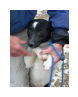

dog test\10.jpg


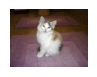

dog test\11.jpg


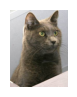

cat test\12.jpg


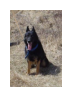

dog test\13.jpg


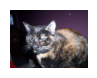

dog test\14.jpg


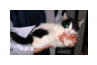

cat test\15.jpg


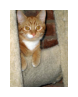

cat test\16.jpg


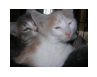

dog test\17.jpg


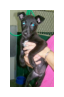

cat test\18.jpg


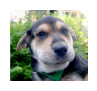

cat test\19.jpg


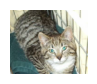

dog test\2.jpg


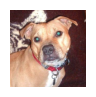

dog test\20.jpg


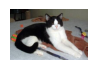

cat test\21.jpg


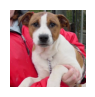

cat test\22.jpg


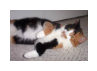

cat test\23.jpg


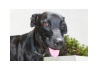

dog test\24.jpg


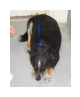

cat test\25.jpg


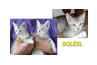

dog test\26.jpg


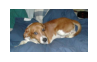

dog test\27.jpg


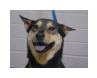

dog test\28.jpg


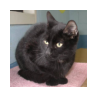

cat test\29.jpg


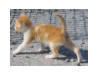

cat test\3.jpg


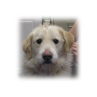

dog test\30.jpg


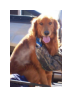

dog test\31.jpg


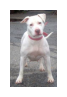

cat test\32.jpg


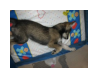

dog test\33.jpg


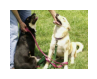

cat test\34.jpg


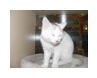

dog test\35.jpg


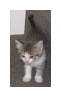

cat test\36.jpg


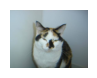

dog test\37.jpg


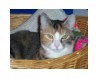

dog test\38.jpg


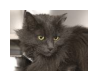

cat test\39.jpg


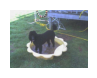

cat test\4.jpg


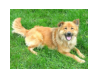

dog test\40.jpg


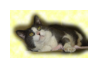

cat test\41.jpg


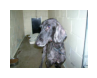

cat test\42.jpg


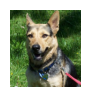

cat test\43.jpg


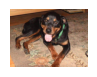

cat test\44.jpg


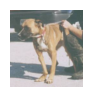

dog test\45.jpg


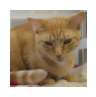

dog test\46.jpg


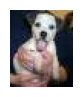

dog test\47.jpg


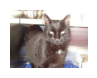

cat test\48.jpg


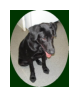

cat test\49.jpg


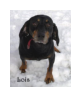

dog test\5.jpg


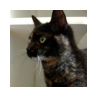

dog test\50.jpg


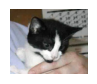

cat test\6.jpg


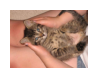

cat test\7.jpg


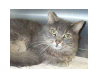

dog test\8.jpg


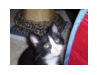

cat test\9.jpg


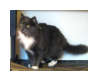

In [36]:


for i in range(len(pred_proba)) :
    if pred_proba[i] > 0.5 :
        print(f"dog {test_gen.filenames[i]}")
    else : 
        print(f"cat {test_gen.filenames[i]}")

    plt.figure(figsize=(1, 1))
    img = mpimg.imread(TEST_PATH + "\\" + test_gen.filenames[i])
    plt.imshow(img)     
    plt.axis('off')
    plt.grid(False)
    plt.show()    

# **전이학습**
* https://keras.io/api/applications/

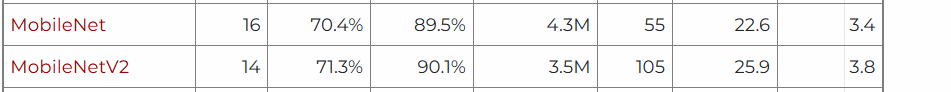

```python
    keras.applications.MobileNet(
    input_shape=None,
    alpha=1.0,
    depth_multiplier=1,
    dropout=0.001,
    include_top=True,
    weights="imagenet",
    input_tensor=None,
    pooling=None,
    classes=1000,
    classifier_activation="softmax",
    name=None,
)

In [48]:
#net_model = MobileNet(input_shape=(240,160,3), include_top=False, weights="imagenet")
net_model = Xception(input_shape=(240,160,3), include_top=False, weights="imagenet")

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [49]:
net_model.trainable = False

In [50]:
model = Sequential([
    net_model,
    GlobalAveragePooling2D(),
    Dense(units=128, activation='relu'),
    Dense(units=1,   activation='sigmoid')
])

In [44]:
pred_proba = model.predict(test_gen)
pred_proba[:5]

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 283ms/step


array([[0.7355919 ],
       [0.86745834],
       [0.62889194],
       [0.5130726 ],
       [0.72042155]], dtype=float32)

dog test\1.jpg


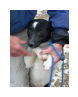

dog test\10.jpg


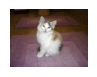

dog test\11.jpg


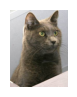

dog test\12.jpg


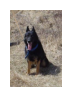

dog test\13.jpg


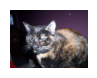

dog test\14.jpg


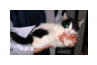

cat test\15.jpg


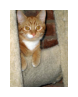

cat test\16.jpg


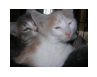

cat test\17.jpg


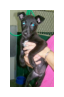

dog test\18.jpg


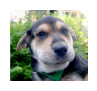

cat test\19.jpg


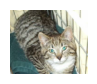

dog test\2.jpg


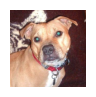

cat test\20.jpg


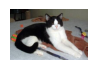

cat test\21.jpg


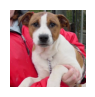

dog test\22.jpg


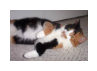

cat test\23.jpg


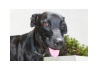

dog test\24.jpg


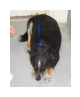

dog test\25.jpg


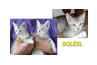

dog test\26.jpg


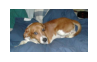

cat test\27.jpg


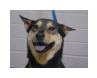

cat test\28.jpg


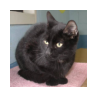

dog test\29.jpg


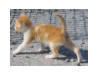

dog test\3.jpg


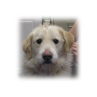

dog test\30.jpg


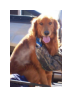

cat test\31.jpg


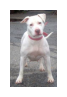

dog test\32.jpg


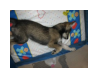

cat test\33.jpg


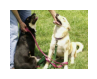

dog test\34.jpg


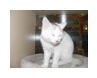

cat test\35.jpg


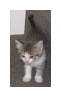

cat test\36.jpg


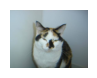

cat test\37.jpg


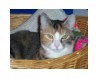

dog test\38.jpg


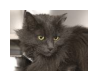

dog test\39.jpg


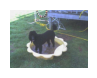

dog test\4.jpg


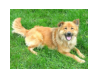

dog test\40.jpg


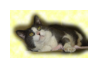

cat test\41.jpg


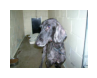

cat test\42.jpg


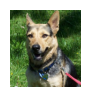

cat test\43.jpg


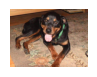

dog test\44.jpg


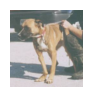

dog test\45.jpg


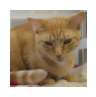

dog test\46.jpg


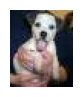

dog test\47.jpg


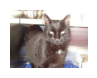

cat test\48.jpg


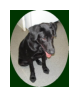

cat test\49.jpg


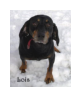

cat test\5.jpg


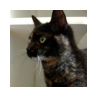

dog test\50.jpg


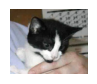

dog test\6.jpg


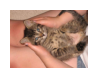

dog test\7.jpg


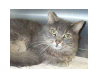

cat test\8.jpg


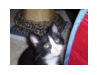

dog test\9.jpg


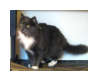

In [51]:
for i in range(len(pred_proba)) :
    if pred_proba[i] > 0.5 :
        print(f"dog {test_gen.filenames[i]}")
    else : 
        print(f"cat {test_gen.filenames[i]}")

    plt.figure(figsize=(1, 1))
    img = mpimg.imread(TEST_PATH + "\\" + test_gen.filenames[i])
    plt.imshow(img)     
    plt.axis('off')
    plt.grid(False)
    plt.show()    